In [17]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import nibabel as nib
import torch
from torch.utils.data import Dataset, DataLoader
from scipy import stats

In [10]:
# ==========================================
# 1. EDA CLÍNICO: Leer metadatos del dataset
# ==========================================
csv_path = r"C:\Users\juan_\Desktop\cv-medical\COBRE_Dataset\participants.tsv"

if os.path.exists(csv_path):
    df_participants = pd.read_csv(csv_path, sep='\t')
    print("--- Primeras filas del registro clínico ---")
    print(df_participants[['participant_id', 'age', 'gender', 'diagnosis']].head())
    
    # Conteo de clases usando la columna correcta: 'diagnosis'
    if 'diagnosis' in df_participants.columns:
        class_counts = df_participants['diagnosis'].value_counts()
        print("\n--- Distribución de Clases (Diagnóstico) ---")
        print(class_counts)
else:
    print("Asegúrate de que el archivo participants.tsv esté en la ruta correcta.")

--- Primeras filas del registro clínico ---
  participant_id  age gender diagnosis
0      sub-10159   30      F   CONTROL
1      sub-10171   24      M   CONTROL
2      sub-10189   49      M   CONTROL
3      sub-10193   40      M   CONTROL
4      sub-10206   21      M   CONTROL

--- Distribución de Clases (Diagnóstico) ---
diagnosis
CONTROL    130
SCHZ        50
BIPOLAR     49
ADHD        43
Name: count, dtype: int64


In [11]:
# ==========================================
# 2. PYTORCH CUSTOM DATASET PARA RESONANCIAS
# ==========================================
class COBREMRI2DDataset(Dataset):
    def __init__(self, data_dir, df_metadata, transform=None):
        self.data_dir = data_dir
        self.transform = transform
        self.subjects = []
        self.labels = []
        
        # Mapeo de diagnóstico a número (ej. CONTROL = 0, Schizophrenia/Patient = 1)
        # Vamos a verificar los valores únicos de diagnosis luego, por ahora guardamos el ID
        for idx, row in df_metadata.iterrows():
            pid = row['participant_id']
            subject_path = os.path.join(self.data_dir, pid, "anat", f"{pid}_T1w.nii.gz")
            if os.path.exists(subject_path):
                self.subjects.append(pid)
                # Guardamos la etiqueta de diagnóstico
                diag = row['diagnosis']
                self.labels.append(0 if diag == 'CONTROL' else 1)
                
        print(f"\nDataset inicializado con {len(self.subjects)} sujetos válidos encontrados.")

    def __len__(self):
        return len(self.subjects)

    def __getitem__(self, idx):
        subject_id = self.subjects[idx]
        label = self.labels[idx]
        img_path = os.path.join(self.data_dir, subject_id, "anat", f"{subject_id}_T1w.nii.gz")
        
        # 1. Cargar volumen 3D con nibabel
        nii_img = nib.load(img_path)
        volume = nii_img.get_fdata()
        
        # 2. Normalización Z-Score (Estándar en imágenes médicas)
        volume = (volume - np.mean(volume)) / (np.std(volume) + 1e-8)
        
        # 3. Extraer el corte axial central (slice 2D)
        slice_idx = volume.shape[2] // 2
        slice_2d = volume[:, :, slice_idx]
        
        # Convertir a tensor de PyTorch [Canal=1, Alto, Ancho]
        tensor_slice = torch.tensor(slice_2d, dtype=torch.float32).unsqueeze(0)
        
        return tensor_slice, torch.tensor(label, dtype=torch.long)

In [12]:
# Instanciar y probar el DataLoader
dataset = COBREMRI2DDataset(data_dir=r"C:\Users\juan_\Desktop\cv-medical\COBRE_Dataset", df_metadata=df_participants)
dataloader = DataLoader(dataset, batch_size=4, shuffle=True)

# Probar un batch rápido con etiquetas
for batch_images, batch_labels in dataloader:
    print(f"\n Forma del Batch de Tensores: {batch_images.shape}") # Esperado: torch.Size([4, 1, 256, 256])
    print(f" Etiquetas del Batch (0: Control, 1: Paciente): {batch_labels}")
    break


Dataset inicializado con 265 sujetos válidos encontrados.

 Forma del Batch de Tensores: torch.Size([4, 1, 176, 256])
 Etiquetas del Batch (0: Control, 1: Paciente): tensor([1, 1, 0, 1])


## Análisis estadístico

In [20]:
import seaborn as sns

In [13]:
csv_path = r"C:\Users\juan_\Desktop\cv-medical\COBRE_Dataset\participants.tsv"
df = pd.read_csv(csv_path, sep='\t')

In [16]:
# 1. Cargar metadatos clínicos
csv_path = r"C:\Users\juan_\Desktop\cv-medical\COBRE_Dataset\participants.tsv"
df = pd.read_csv(csv_path, sep='\t')

print("==================================================")
print("       ESTUDIO ESTADÍSTICO Y DEMOGRÁFICO COBRE    ")
print("==================================================\n")

# 2. Resumen de diagnósticos
print("--- Conteo y Proporción por Diagnóstico ---")
diag_counts = df['diagnosis'].value_counts()
diag_percent = df['diagnosis'].value_counts(normalize=True) * 100
summary_diag = pd.DataFrame({'Cantidad': diag_counts, 'Porcentaje (%)': diag_percent})
print(summary_diag)
print(f"\nTotal de sujetos en la tabla clínica: {len(df)}")

# 3. Estadísticas descriptivas de Edad por Grupo
print("\n--- Estadísticas de Edad (Media, Desviación, Mediana, IQR) ---")
age_stats = df.groupby('diagnosis')['age'].agg(
    n='count',
    Media='mean',
    Std='std',
    Mediana='median',
    IQR=lambda x: np.percentile(x, 75) - np.percentile(x, 25)
)
print(age_stats.round(2))

       ESTUDIO ESTADÍSTICO Y DEMOGRÁFICO COBRE    

--- Conteo y Proporción por Diagnóstico ---
           Cantidad  Porcentaje (%)
diagnosis                          
CONTROL         130       47.794118
SCHZ             50       18.382353
BIPOLAR          49       18.014706
ADHD             43       15.808824

Total de sujetos en la tabla clínica: 272

--- Estadísticas de Edad (Media, Desviación, Mediana, IQR) ---
             n  Media    Std  Mediana    IQR
diagnosis                                   
ADHD        43  33.09  10.76     30.0  21.00
BIPOLAR     49  35.29   9.03     36.0  17.00
CONTROL    130  31.26   8.74     28.0  15.00
SCHZ        50  36.46   8.88     37.5  14.75


In [18]:
# 4. Prueba estadística de hipótesis (ANOVA para múltiples grupos en Edad)
# Extraemos las listas de edades para cada grupo de diagnóstico presente
age_groups_list = [group['age'].dropna().values for name, group in df.groupby('diagnosis')]
f_stat, p_val_anova = stats.f_oneway(*age_groups_list)

print(f"\nPrueba ANOVA (Edad entre los 4 grupos): F = {f_stat:.4f}, p-value = {p_val_anova:.4f}")
if p_val_anova < 0.05:
    print("⚠️ Alerta estadística: Hay diferencias significativas de edad entre al menos uno de los grupos (variable a tener en cuenta).")
else:
    print("✅ Las edades están bien distribuidas globalmente entre los 4 grupos (sin diferencias significativas).")

# 5. Análisis de Género (Tabla de Contingencia y Chi-cuadrado)
print("\n--- Distribución de Género por Diagnóstico ---")
contingency_table = pd.crosstab(df['diagnosis'], df['gender'], margins=True)
print(contingency_table)

chi2, p_chi, dof, ex = stats.chi2_contingency(pd.crosstab(df['diagnosis'], df['gender']))
print(f"\nPrueba Chi-cuadrado de independencia (Género vs Diagnóstico): p-value = {p_chi:.4f}")


Prueba ANOVA (Edad entre los 4 grupos): F = 4.9001, p-value = 0.0025
⚠️ Alerta estadística: Hay diferencias significativas de edad entre al menos uno de los grupos (variable a tener en cuenta).

--- Distribución de Género por Diagnóstico ---
gender       F    M  All
diagnosis               
ADHD        22   21   43
BIPOLAR     21   28   49
CONTROL     62   68  130
SCHZ        12   38   50
All        117  155  272

Prueba Chi-cuadrado de independencia (Género vs Diagnóstico): p-value = 0.0213


C:\Users\juan_\AppData\Local\Temp\ipykernel_4336\2920591821.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='diagnosis', y='age', data=df, palette='Set2', ax=axes[0], width=0.4, boxprops=dict(alpha=0.8))


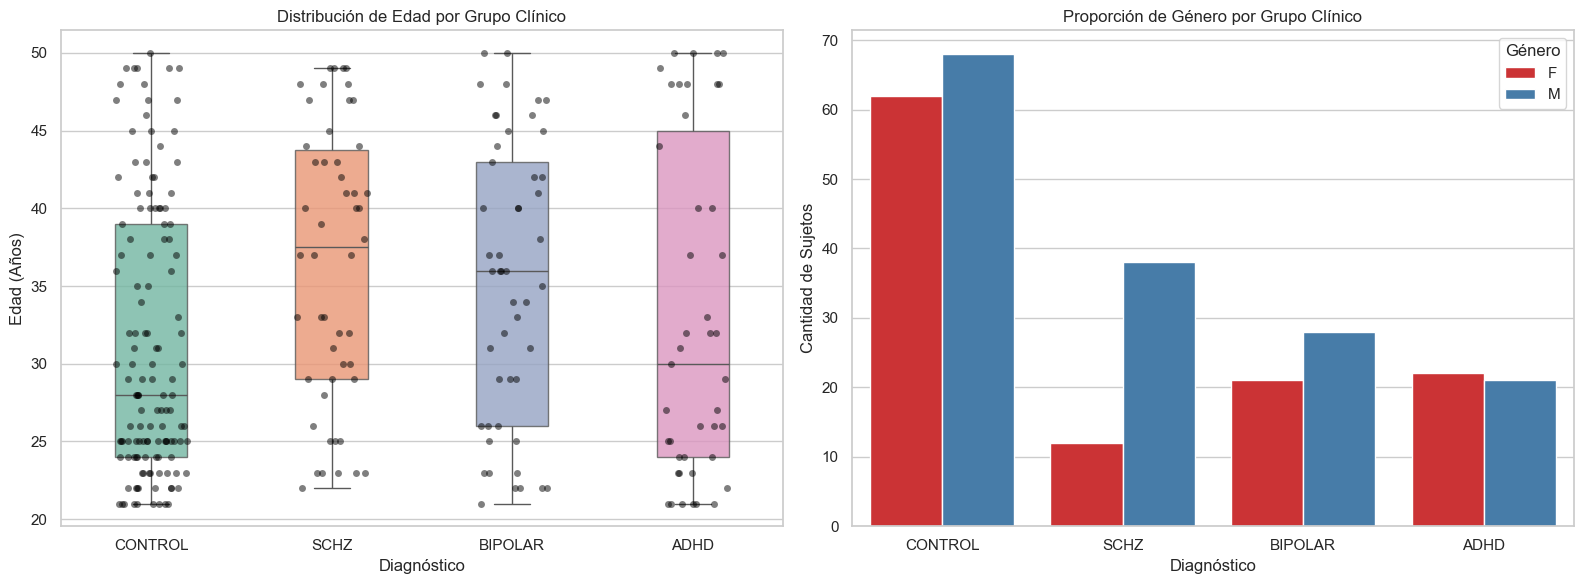

In [21]:
# ==========================================
# 6. VISUALIZACIÓN GRÁFICA PARA EL REPORTE
# ==========================================
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico 1: Boxplot de edades por diagnóstico
sns.boxplot(x='diagnosis', y='age', data=df, palette='Set2', ax=axes[0], width=0.4, boxprops=dict(alpha=0.8))
sns.stripplot(x='diagnosis', y='age', data=df, color='black', alpha=0.5, jitter=0.2, ax=axes[0])
axes[0].set_title('Distribución de Edad por Grupo Clínico')
axes[0].set_xlabel('Diagnóstico')
axes[0].set_ylabel('Edad (Años)')

# Gráfico 2: Proporción de Género por Diagnóstico
sns.countplot(x='diagnosis', hue='gender', data=df, palette='Set1', ax=axes[1])
axes[1].set_title('Proporción de Género por Grupo Clínico')
axes[1].set_xlabel('Diagnóstico')
axes[1].set_ylabel('Cantidad de Sujetos')
axes[1].legend(title='Género')

plt.tight_layout()
plt.show()